## **Import Libraries**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize


## **Load Preprocessed Dataset**

In [ ]:
# Load Preprocessed Dataset
from google.colab import files
uploaded = files.upload()
file = pd.read_csv('preprocessed_classification.csv')
file.head()

Saving preprocessed_classification.csv to preprocessed_classification.csv


,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
0,rural,2,0.29,70,night,rainy,False,True,evening,False,False,1,High
1,highway,1,0.34,25,dim,clear,False,False,morning,False,False,3,Medium
2,rural,2,0.76,70,night,foggy,True,False,evening,True,True,1,High
3,rural,3,0.37,70,night,foggy,True,False,morning,False,True,0,Medium
4,highway,3,0.39,45,dim,rainy,False,True,morning,False,False,0,Low


In [ ]:
boolean_features = ['road_signs_present', 'public_road', 'holiday', 'school_season']
categorical_features = ['road_type', 'lighting', 'weather', 'time_of_day']

# Convert Boolean Features to 0/1
for col in boolean_features:
    file.loc[:, col] = file[col].astype(int)

# Label Encode Categorical Features
label_encoders = {}

for col in categorical_features:
    le = LabelEncoder()
    file.loc[:, col] = le.fit_transform(file[col])
    label_encoders[col] = le

    # Display Categorical Column and Their Unique Label
    print(f"Mapping for column '{col}':")
    for class_index, class_label in enumerate(le.classes_):
        print(f"{class_label}: {class_index}")
    print("\n")



Mapping for column 'road_type':
highway: 0
rural: 1
urban: 2


Mapping for column 'lighting':
daylight: 0
dim: 1
night: 2


Mapping for column 'weather':
clear: 0
foggy: 1
rainy: 2


Mapping for column 'time_of_day':
afternoon: 0
evening: 1
morning: 2




/tmp/ipython-input-2474510808.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 ... 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  file.loc[:, col] = file[col].astype(int)
/tmp/ipython-input-2474510808.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 0 0 ... 0 1 1]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  file.loc[:, col] = file[col].astype(int)
/tmp/ipython-input-2474510808.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 1 ... 1 0 1]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  file.loc[:, col] = file[col].astype(int)
/tmp/ipython-input-2474510808.py:6: FutureWarning: Setting an item of incompatible dtype is de

In [ ]:
risk_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}

file['accident_risk'] = file['accident_risk'].map(risk_mapping)
print(file['accident_risk'].unique())

[2 1 0]


In [ ]:
le_target = LabelEncoder()

file['accident_risk'] = le_target.fit_transform(file['accident_risk'])

print(file['accident_risk'].unique())
print(le_target.classes_)


[0 2 1]
['High' 'Low' 'Medium']


Splitting Dataset

In [ ]:
X = file.drop(columns=['accident_risk'])
y = file['accident_risk']

In [ ]:
# Split dataset (80% Training 20 % Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

print(y_test[:10])

Shape of X_train: (79977, 12)
Shape of X_test: (19995, 12)
Shape of y_train: (79977,)
Shape of y_test: (19995,)
37316    1
36047    1
53792    1
17376    2
32459    2
84671    1
866      2
94816    2
16458    2
3416     0
Name: accident_risk, dtype: int64


## **Model Development & Training**

In [ ]:
# Random Forest Classifier
rf = RandomForestClassifier(
    n_estimators = 100,
    random_state = 42
)

In [ ]:
# Model Training
print("Training model...")
rf.fit(X_train, y_train)
print("Model training completed.")

# Getting prediction using Test Set
rf_pred = rf.predict(X_test)

Training model...
Model training completed.


## **Model Evaluation**

In [ ]:
# Classification Report
accuracy = accuracy_score(y_test, rf_pred) * 100
print(f"Random Forest Classifier Accuracy: {accuracy}%")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))



Random Forest Classifier Accuracy: 88.01200300075018%

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.75      0.80      2365
           1       0.86      0.84      0.85      5059
           2       0.89      0.92      0.91     12571

    accuracy                           0.88     19995
   macro avg       0.87      0.84      0.85     19995
weighted avg       0.88      0.88      0.88     19995



## **Hyperparameter Tuning**

In [ ]:
param_dist = {
    'n_estimators': randint(100, 200),
    'max_depth': randint(5, 60),
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 8),
    'max_features': ['sqrt', 'log2', None]
}

# Random Forest Classifier
rf = RandomForestClassifier(random_state=42)

# Initialize RandomizedSearchCV
random_search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

# Hyperparameter Tuning
print("Performing hyperparameter tuning...")
random_search.fit(X_train, y_train)
print("Hyperparameter tuning completed.")

# Get the best parameters
best_params = random_search.best_params_
print("Best parameters found:")
print(best_params)

Performing hyperparameter tuning...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Hyperparameter tuning completed.
Best parameters found:
{'max_depth': 11, 'max_features': 'sqrt', 'min_samples_leaf': 7, 'min_samples_split': 4, 'n_estimators': 177}


In [ ]:
# Train the Random Forest model with the best parameters
rf_best = RandomForestClassifier(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    min_samples_split=best_params['min_samples_split'],
    min_samples_leaf=best_params['min_samples_leaf'],
    max_features=best_params['max_features'],
    random_state=42
)

In [ ]:
# Train Model on Best Parameters
print("Training the optimized Random Forest model...")
rf_best.fit(X_train, y_train)
print("Model training completed.")

# Get prediction on Test Set
rf_best_pred = rf_best.predict(X_test)

Training the optimized Random Forest model...
Model training completed.


In [ ]:
# Classification Report
accuracy = accuracy_score(y_test, rf_best_pred) * 100
print(f"Random Forest Classifier Accuracy: {accuracy}%")

print("\nClassification Report:")
print(classification_report(y_test, rf_best_pred))

Random Forest Classifier Accuracy: 88.5571392848212%

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.73      0.81      2365
           1       0.88      0.83      0.85      5059
           2       0.89      0.94      0.91     12571

    accuracy                           0.89     19995
   macro avg       0.89      0.83      0.86     19995
weighted avg       0.89      0.89      0.88     19995



## **Model Visualization**

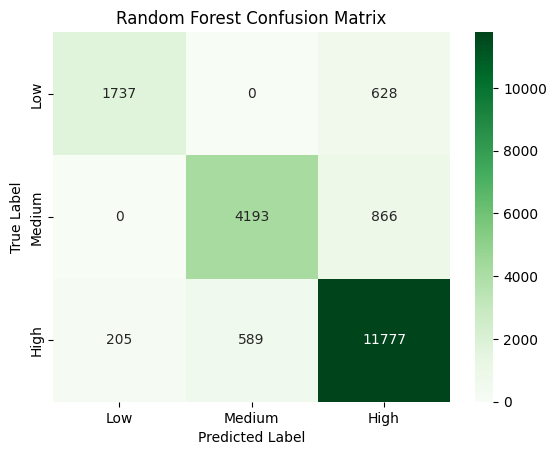

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, rf_best_pred)

class_labels = ["Low", "Medium", "High"]

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Greens',
            xticklabels = class_labels,
            yticklabels = class_labels)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

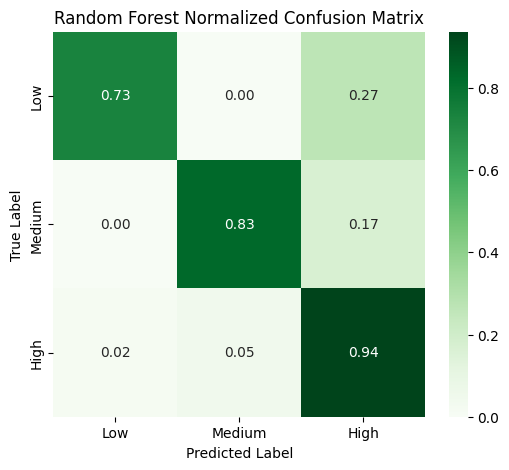

In [ ]:
# Normalized Confusion Matrix

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Random Forest Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
print(rf_best.classes_)


[0 1 2]


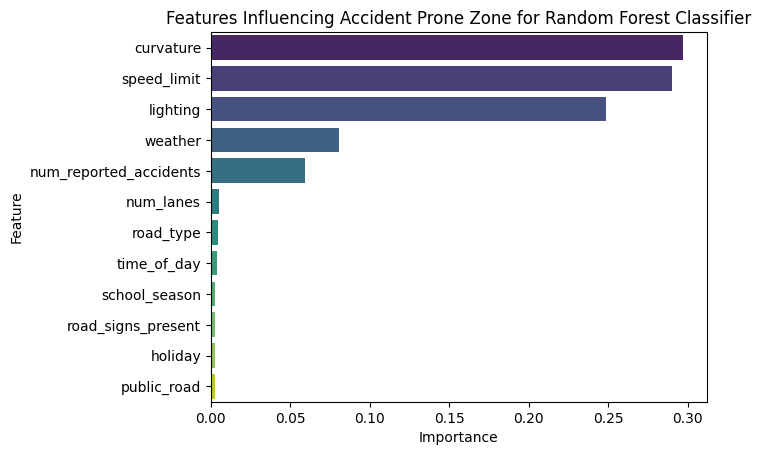

In [ ]:
# Feature Importance Plot
importances = rf_best.feature_importances_
feature_names = X.columns

# Create DataFrame
importance_df = pd.DataFrame({'Feature': feature_names,
                              'Importance': importances})

# Sort by descending order
top_features = importance_df.sort_values(by='Importance', ascending=False)


sns.barplot(x='Importance',
            y='Feature',
            data = top_features,
            palette='viridis',
            hue = 'Feature')
plt.title('Features Influencing Accident Prone Zone for Random Forest Classifier')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

Macro-average ROC AUC: 0.9708317235443492


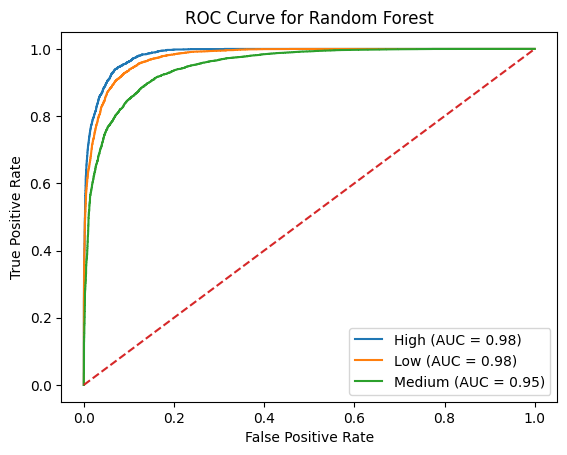

In [ ]:
# Get predicted probabilities
y_prob = rf_best.predict_proba(X_test)

# Get correct class order from the trained model
classes = rf_best.classes_

# Binarize the true labels
y_test_bin = label_binarize(y_test, classes=classes)

# Compute ROC curve and AUC for each class
fpr = {}
tpr = {}
roc_auc = {}

for i, cls in enumerate(classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])


macro_auc = roc_auc_score(y_test_bin, y_prob, average="macro")

print("Macro-average ROC AUC:", macro_auc)

plt.figure()

for i, cls in enumerate(rf_best.classes_):
    class_name = le_target.classes_[cls]
    plt.plot(
        fpr[i],
        tpr[i],
        label=f"{class_name} (AUC = {roc_auc[i]:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Random Forest")
plt.legend()
plt.show()


In [ ]:
import joblib
import os

PROJECT_DIR = "/content/drive/MyDrive/STL"
os.makedirs(PROJECT_DIR, exist_ok=True)
joblib.dump(rf_best, f"{PROJECT_DIR}/randomforest.pkl")
np.save(f"{PROJECT_DIR}/X_test.npy", X_test)
np.save(f"{PROJECT_DIR}/y_test.npy", y_test)
